# Ensemble (ML + DL) and decision layer

This notebook combines the models you have trained into one stronger detector, then turns its output into alert levels.

**Rules that keep the evaluation honest**
- Every choice (which models, voting weights, thresholds, which ensemble method) is made on the **validation** set.
- The **testing set** is used only to report the final results.
- Stacking is trained on **out-of-fold** validation predictions, so it never scores itself on data it was fitted on.

**What it does**
1. Loads whichever saved models exist (ML and DL) and collects their probabilities.
2. **Binary ensemble** (normal vs attack): soft voting, weighted voting, stacking.
3. **Multiclass ensemble:** the same three methods, plus **per-class calibration**, a post-hoc step that rescales class probabilities to raise macro F1 for weak classes such as DoS and Other.
4. Compares everything on the testing set, with **bootstrap confidence intervals** and **McNemar's test** against the best single model.
5. **Decision layer:** turns the ensemble (and the autoencoder, if available) into High / Medium / Unusual / Normal alerts and an attack family.
6. Saves everything the live detector needs.

Run `prepare_test_set.ipynb` first, and run as many model notebooks as you can. Missing models are skipped.

## 1. Imports and config

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

# models to try (a model is used only if its saved files exist)
CANDIDATES = ["rf", "xgb", "lgbm", "catboost", "extratrees", "mlp", "ann", "dnn", "resmlp", "fttransformer", "cnn", "rnn"]
MAX_MODELS = 5            # the ensemble uses the best N models (by validation score)
TARGET_FPR_HIGH = 0.01    # false-alarm rate allowed for "high" alerts
N_BOOTSTRAP = 300         # resamples for the confidence intervals

rng = np.random.default_rng(SEED)

## 2. Load the validation and testing data

In [2]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
if not (proc / "unsw_nb15_test.npz").exists():
    raise FileNotFoundError("processed/unsw_nb15_test.npz not found. Run prepare_test_set.ipynb first.")
test = np.load(proc / "unsw_nb15_test.npz")
meta = json.loads((proc / "meta.json").read_text())

X_val, yb_val, ym_val = data["X_val"].astype("float32"), data["y_bin_val"].astype(int), data["y_multi_val"].astype(int)
X_test, yb_test, ym_test = test["X_test"].astype("float32"), test["y_bin_test"].astype(int), test["y_multi_test"].astype(int)
class_names = meta["class_names"]
K = len(class_names)
print(f"validation: {len(X_val):,} rows   test: {len(X_test):,} rows   classes: {class_names}")

validation: 35,069 rows   test: 82,332 rows   classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 3. Metric helpers

`fast_*` functions compute F1 from a confusion matrix, so the bootstrap (hundreds of resamples) stays quick.

In [3]:
def bin_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"threshold": round(float(thr), 4), "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "false_pos_rate": fp / max(fp + tn, 1), "roc_auc": roc_auc_score(y, p)}


def multi_metrics(y, pred):
    return {"accuracy": accuracy_score(y, pred),
            "macro_precision": precision_score(y, pred, average="macro", zero_division=0),
            "macro_recall": recall_score(y, pred, average="macro", zero_division=0),
            "macro_f1": f1_score(y, pred, average="macro"),
            "weighted_f1": f1_score(y, pred, average="weighted")}


def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return float(thr[np.argmax(f1)])


def fast_macro_f1(y, pred, k=K):
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float)
    denom = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0).mean()


def fast_binary_f1(y, pred):
    tp = np.sum((y == 1) & (pred == 1)); fp = np.sum((y == 0) & (pred == 1)); fn = np.sum((y == 1) & (pred == 0))
    return 2 * tp / max(2 * tp + fp + fn, 1)


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

## 4. Load every available model and collect probabilities

Each model gives an attack probability (binary) and a class-probability vector (multiclass) for the validation and testing rows.

In [4]:
def load_predictor(tag, kind):
    """Return f(X) -> probabilities, or None if the model's files are missing."""
    mdir = Path(MODEL_DIR)
    if tag in ("rf", "extratrees", "lgbm"):
        f = mdir / f"{tag}_{kind}.joblib"
        if not f.exists():
            return None
        m = joblib.load(f)
        return lambda X: m.predict_proba(X)
    if tag == "xgb":
        f = mdir / f"xgb_{kind}.json"
        if not f.exists():
            return None
        import xgboost as xgb
        m = xgb.XGBClassifier(); m.load_model(f)
        return lambda X: m.predict_proba(X)
    if tag == "catboost":
        f = mdir / f"catboost_{kind}.cbm"
        if not f.exists():
            return None
        from catboost import CatBoostClassifier
        m = CatBoostClassifier(); m.load_model(str(f))
        return lambda X: m.predict_proba(X)
    f = mdir / f"{tag}_{kind}.keras"                       # all neural networks
    if not f.exists():
        return None
    import keras
    try:
        from nids_layers import FeatureTokenizer           # registers the custom layer
    except ImportError:
        pass
    m = keras.models.load_model(f)
    return lambda X: m.predict(X, batch_size=4096, verbose=0)


def attack_proba(p):
    p = np.asarray(p)
    return p[:, 1] if p.ndim == 2 and p.shape[1] == 2 else p.ravel()


pb_val, pb_test, pm_val, pm_test = {}, {}, {}, {}
for tag in CANDIDATES:
    for kind in ("binary", "multiclass"):
        try:
            fn = load_predictor(tag, kind)
            if fn is None:
                continue
            pv, pt = fn(X_val), fn(X_test)
            if kind == "binary":
                pb_val[tag], pb_test[tag] = attack_proba(pv), attack_proba(pt)
            else:
                pm_val[tag], pm_test[tag] = np.asarray(pv), np.asarray(pt)
        except Exception as e:
            print(f"skipping {tag} {kind}: {type(e).__name__}: {str(e)[:120]}")
print("binary models found:    ", sorted(pb_val))
print("multiclass models found:", sorted(pm_val))
if len(pb_val) < 2 or len(pm_val) < 2:
    raise RuntimeError("Need at least two binary and two multiclass models. Run more model notebooks first.")

binary models found:     ['ann', 'catboost', 'cnn', 'dnn', 'extratrees', 'fttransformer', 'lgbm', 'mlp', 'resmlp', 'rf', 'rnn', 'xgb']
multiclass models found: ['ann', 'catboost', 'cnn', 'dnn', 'extratrees', 'fttransformer', 'lgbm', 'mlp', 'resmlp', 'rf', 'rnn', 'xgb']


## 5. Single models: validation ranking and test results

Binary models are scored at their own best-F1 threshold (chosen on validation), so no model is penalised for a badly placed 0.5 cut-off. ROC-AUC is threshold-free.

In [5]:
bin_thr = {t: best_f1_threshold(yb_val, pb_val[t]) for t in pb_val}
bin_val_f1 = {t: f1_score(yb_val, (pb_val[t] >= bin_thr[t]).astype(int)) for t in pb_val}
multi_val_f1 = {t: f1_score(ym_val, pm_val[t].argmax(1), average="macro") for t in pm_val}

rows = [{"model": t, "val_f1": bin_val_f1[t], **bin_metrics(yb_test, pb_test[t], bin_thr[t])} for t in pb_val]
single_bin = pd.DataFrame(rows).sort_values("val_f1", ascending=False).reset_index(drop=True)
print("BINARY, single models (test metrics at the validation-tuned threshold)")
display(single_bin.round(4))

rows = [{"model": t, "val_macro_f1": multi_val_f1[t], **multi_metrics(ym_test, pm_test[t].argmax(1))} for t in pm_val]
single_multi = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
print("MULTICLASS, single models (test metrics)")
display(single_multi.round(4))

members_bin = list(single_bin["model"][:MAX_MODELS])
members_multi = list(single_multi["model"][:MAX_MODELS])
print("ensemble members, binary:    ", members_bin)
print("ensemble members, multiclass:", members_multi)

BINARY, single models (test metrics at the validation-tuned threshold)


,model,val_f1,threshold,accuracy,precision,recall,f1,false_pos_rate,roc_auc
0,xgb,0.9739,0.2690,0.8577,0.8031,0.9825,0.8838,0.2952,0.9796
1,lgbm,0.9738,0.2853,0.8620,0.8083,0.9822,0.8869,0.2853,0.9804
2,catboost,0.9734,0.2935,0.8645,0.8128,0.9797,0.8885,0.2765,0.9801
3,extratrees,0.9725,0.3442,0.8508,0.7907,0.9915,0.8798,0.3216,0.9813
4,rf,0.9716,0.3247,0.8498,0.7881,0.9946,0.8794,0.3276,0.9814
5,fttransformer,0.9694,0.2342,0.8488,0.7889,0.9904,0.8782,0.3247,0.9790
6,resmlp,0.9675,0.2246,0.8301,0.7689,0.9886,0.8650,0.3640,0.9769
7,dnn,0.9664,0.2784,0.8324,0.7715,0.9881,0.8665,0.3585,0.9755
8,cnn,0.9662,0.1880,0.8128,0.7485,0.9940,0.8539,0.4092,0.9713
9,mlp,0.9659,0.2699,0.8233,0.7610,0.9901,0.8605,0.3811,0.9725


MULTICLASS, single models (test metrics)


,model,val_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,fttransformer,0.7058,0.6730,0.6050,0.6457,0.5841,0.7235
1,resmlp,0.7032,0.6689,0.5984,0.6544,0.5815,0.7185
2,cnn,0.7000,0.6837,0.6035,0.6565,0.5893,0.7270
3,mlp,0.6985,0.6737,0.5860,0.6476,0.5761,0.7192
4,catboost,0.6968,0.6817,0.6110,0.6612,0.5926,0.7289
5,dnn,0.6950,0.6744,0.5851,0.6442,0.5754,0.7194
6,ann,0.6912,0.6750,0.5873,0.6622,0.5827,0.7165
7,lgbm,0.6911,0.6910,0.6259,0.6833,0.6049,0.7383
8,xgb,0.6761,0.6904,0.6256,0.6844,0.6037,0.7378
9,rf,0.6239,0.7306,0.6232,0.6657,0.6110,0.7698


ensemble members, binary:     ['xgb', 'lgbm', 'catboost', 'extratrees', 'rf']
ensemble members, multiclass: ['fttransformer', 'resmlp', 'cnn', 'mlp', 'catboost']


## 6. Binary ensemble

- **Soft voting:** average the attack probabilities.
- **Weighted voting:** weights proportional to each model's validation F1.
- **Stacking:** logistic regression on the models' logits, trained on validation predictions. Its validation score uses out-of-fold predictions, so it is not inflated.

In [6]:
Pv = np.column_stack([pb_val[t] for t in members_bin])
Pt = np.column_stack([pb_test[t] for t in members_bin])

w_bin = np.array([bin_val_f1[t] for t in members_bin]); w_bin = w_bin / w_bin.sum()

# stacking: pick C by cross-validation, get out-of-fold validation predictions, then fit on all validation rows
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_lr = LogisticRegressionCV(Cs=8, cv=skf, class_weight="balanced", max_iter=2000, scoring="f1").fit(logit(Pv), yb_val)
stack_bin = LogisticRegression(C=float(cv_lr.C_[0]), class_weight="balanced", max_iter=2000).fit(logit(Pv), yb_val)
stack_oof = cross_val_predict(LogisticRegression(C=float(cv_lr.C_[0]), class_weight="balanced", max_iter=2000),
                              logit(Pv), yb_val, cv=skf, method="predict_proba")[:, 1]

ens_bin = {   # name -> (validation scores, test scores)
    "soft voting":     (Pv.mean(1), Pt.mean(1)),
    "weighted voting": (Pv @ w_bin, Pt @ w_bin),
    "stacking":        (stack_oof, stack_bin.predict_proba(logit(Pt))[:, 1]),
}
ens_bin_thr = {n: best_f1_threshold(yb_val, v) for n, (v, _) in ens_bin.items()}
ens_bin_val_f1 = {n: f1_score(yb_val, (v >= ens_bin_thr[n]).astype(int)) for n, (v, _) in ens_bin.items()}

rows = [{"model": f"ENSEMBLE {n}", "val_f1": ens_bin_val_f1[n], **bin_metrics(yb_test, t, ens_bin_thr[n])}
        for n, (_, t) in ens_bin.items()]
binary_all = pd.concat([pd.DataFrame(rows), single_bin], ignore_index=True).sort_values("val_f1", ascending=False)
display(binary_all.reset_index(drop=True).round(4))

best_bin_method = max(ens_bin_val_f1, key=ens_bin_val_f1.get)       # chosen on VALIDATION only
print("binary ensemble chosen on validation:", best_bin_method)

c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details

,model,val_f1,threshold,accuracy,precision,recall,f1,false_pos_rate,roc_auc
0,ENSEMBLE soft voting,0.9743,0.3157,0.8603,0.8037,0.9876,0.8862,0.2955,0.9818
1,ENSEMBLE weighted voting,0.9743,0.3157,0.8603,0.8037,0.9876,0.8862,0.2955,0.9818
2,ENSEMBLE stacking,0.9740,0.3901,0.8650,0.8114,0.9834,0.8891,0.2801,0.9814
3,xgb,0.9739,0.2690,0.8577,0.8031,0.9825,0.8838,0.2952,0.9796
4,lgbm,0.9738,0.2853,0.8620,0.8083,0.9822,0.8869,0.2853,0.9804
5,catboost,0.9734,0.2935,0.8645,0.8128,0.9797,0.8885,0.2765,0.9801
6,extratrees,0.9725,0.3442,0.8508,0.7907,0.9915,0.8798,0.3216,0.9813
7,rf,0.9716,0.3247,0.8498,0.7881,0.9946,0.8794,0.3276,0.9814
8,fttransformer,0.9694,0.2342,0.8488,0.7889,0.9904,0.8782,0.3247,0.9790
9,resmlp,0.9675,0.2246,0.8301,0.7689,0.9886,0.8650,0.3640,0.9769


binary ensemble chosen on validation: soft voting


## 7. Multiclass ensemble and per-class calibration

Calibration multiplies each class probability by a learned factor before taking the argmax. A weak class such as DoS gets a boost when that raises macro F1 on the validation set. The factors are fitted on validation (out-of-fold for stacking). Because that would make the calibrated model look better on the very rows it was tuned on, its validation score is a **cross-validated** estimate (tune on 4/5 of validation, score on the other 1/5), so choosing it is a fair decision. The testing set then shows whether the gain is real.

In [7]:
Mv = [pm_val[t] for t in members_multi]
Mt = [pm_test[t] for t in members_multi]
w_multi = np.array([multi_val_f1[t] for t in members_multi]); w_multi = w_multi / w_multi.sum()

soft_v, soft_t = np.mean(Mv, axis=0), np.mean(Mt, axis=0)
wtd_v, wtd_t = np.tensordot(w_multi, np.array(Mv), 1), np.tensordot(w_multi, np.array(Mt), 1)

Fv, Ft = np.hstack(Mv), np.hstack(Mt)                           # stacking features: every model's class probabilities
cv_m = LogisticRegressionCV(Cs=5, cv=3, class_weight="balanced", max_iter=500, scoring="f1_macro").fit(Fv, ym_val)
C_m = float(cv_m.C_[0])
stack_multi = LogisticRegression(C=C_m, class_weight="balanced", max_iter=500).fit(Fv, ym_val)
stack_multi_oof = cross_val_predict(LogisticRegression(C=C_m, class_weight="balanced", max_iter=500),
                                    Fv, ym_val, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                                    method="predict_proba")

ens_multi = {"soft voting": (soft_v, soft_t), "weighted voting": (wtd_v, wtd_t),
             "stacking": (stack_multi_oof, stack_multi.predict_proba(Ft))}
ens_multi_val_f1 = {n: fast_macro_f1(ym_val, v.argmax(1)) for n, (v, _) in ens_multi.items()}

c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details

In [8]:
def tune_class_scale(P, y, rounds=3, grid=np.exp(np.linspace(-1.5, 1.5, 13))):
    """Coordinate ascent on one multiplicative factor per class to maximise macro F1."""
    scale = np.ones(P.shape[1])
    best = fast_macro_f1(y, (P * scale).argmax(1))
    for _ in range(rounds):
        for k in range(P.shape[1]):
            for g in grid:
                trial = scale.copy(); trial[k] = g
                s = fast_macro_f1(y, (P * trial).argmax(1))
                if s > best + 1e-9:
                    best, scale = s, trial
    return scale, best


best_multi_method = max(ens_multi_val_f1, key=ens_multi_val_f1.get)
base_v, base_t = ens_multi[best_multi_method]
class_scale, _ = tune_class_scale(base_v, ym_val)          # final factors, fitted on all validation rows

# honest estimate of the benefit: tune on 4/5 of validation, score on the held-out 1/5, repeat
gains = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(base_v, ym_val):
    sc, _ = tune_class_scale(base_v[tr], ym_val[tr])
    gains.append(fast_macro_f1(ym_val[te], (base_v[te] * sc).argmax(1)) - fast_macro_f1(ym_val[te], base_v[te].argmax(1)))
cal_gain = float(np.mean(gains))
print(f"class calibration, cross-validated gain in macro F1: {cal_gain:+.4f}  (std {np.std(gains):.4f})")

ens_multi[f"{best_multi_method} + class calibration"] = (base_v * class_scale, base_t * class_scale)
ens_multi_val_f1[f"{best_multi_method} + class calibration"] = ens_multi_val_f1[best_multi_method] + cal_gain

print("class scale factors:", {n: round(float(v), 2) for n, v in zip(class_names, class_scale)})
rows = [{"model": f"ENSEMBLE {n}", "val_macro_f1": ens_multi_val_f1[n], **multi_metrics(ym_test, t.argmax(1))}
        for n, (_, t) in ens_multi.items()]
multiclass_all = pd.concat([pd.DataFrame(rows), single_multi], ignore_index=True).sort_values("val_macro_f1", ascending=False)
display(multiclass_all.reset_index(drop=True).round(4))

final_multi_method = max(ens_multi_val_f1, key=ens_multi_val_f1.get)    # chosen on VALIDATION only
print("multiclass ensemble chosen on validation:", final_multi_method)

class calibration, cross-validated gain in macro F1: +0.0258  (std 0.0033)
class scale factors: {'Normal': 2.12, 'DoS': 1.0, 'Reconnaissance': 0.37, 'Fuzzers': 1.0, 'Exploits': 1.65, 'Generic': 2.72, 'Other': 0.61}


,model,val_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,ENSEMBLE stacking + class calibration,0.7383,0.7084,0.6148,0.6628,0.6072,0.7470
1,ENSEMBLE stacking,0.7125,0.6837,0.6200,0.6893,0.6011,0.7305
2,ENSEMBLE weighted voting,0.7068,0.6777,0.6064,0.6546,0.5880,0.7265
3,ENSEMBLE soft voting,0.7068,0.6777,0.6063,0.6546,0.5880,0.7265
4,fttransformer,0.7058,0.6730,0.6050,0.6457,0.5841,0.7235
5,resmlp,0.7032,0.6689,0.5984,0.6544,0.5815,0.7185
6,cnn,0.7000,0.6837,0.6035,0.6565,0.5893,0.7270
7,mlp,0.6985,0.6737,0.5860,0.6476,0.5761,0.7192
8,catboost,0.6968,0.6817,0.6110,0.6612,0.5926,0.7289
9,dnn,0.6950,0.6744,0.5851,0.6442,0.5754,0.7194


multiclass ensemble chosen on validation: stacking + class calibration


## 8. Final test results, per class, with confidence intervals and significance

The chosen ensemble is compared with the best single model (picked on validation). Confidence intervals come from resampling the test rows. McNemar's test asks whether the two models make different mistakes more often than chance would explain.

In [9]:
final_bin_v, final_bin_t = ens_bin[best_bin_method]
final_bin_thr = ens_bin_thr[best_bin_method]
final_multi_t = ens_multi[final_multi_method][1]
final_multi_pred = final_multi_t.argmax(1)

best_single_bin, best_single_multi = members_bin[0], members_multi[0]
sb_pred = (pb_test[best_single_bin] >= bin_thr[best_single_bin]).astype(int)
eb_pred = (final_bin_t >= final_bin_thr).astype(int)
sm_pred = pm_test[best_single_multi].argmax(1)


def bootstrap(metric, y, pred_a, pred_b, n=N_BOOTSTRAP):
    a, b = [], []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        a.append(metric(y[idx], pred_a[idx])); b.append(metric(y[idx], pred_b[idx]))
    a, b = np.array(a), np.array(b)
    ci = lambda v: f"{v.mean():.4f}  [{np.percentile(v, 2.5):.4f}, {np.percentile(v, 97.5):.4f}]"
    d = b - a
    return ci(a), ci(b), f"{d.mean():+.4f}  [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]"


def mcnemar(y, pred_a, pred_b):
    ca, cb = pred_a == y, pred_b == y
    b01, b10 = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))      # only A right / only B right
    stat = (abs(b01 - b10) - 1) ** 2 / max(b01 + b10, 1)
    return b01, b10, float(chi2.sf(stat, 1))


rows = []
for task, metric, y, a, b, single_name in [
    ("binary F1", fast_binary_f1, yb_test, sb_pred, eb_pred, best_single_bin),
    ("multiclass macro F1", fast_macro_f1, ym_test, sm_pred, final_multi_pred, best_single_multi)]:
    ci_a, ci_b, ci_d = bootstrap(metric, y, a, b)
    only_a, only_b, p = mcnemar(y, a, b)
    rows.append({"task": task, f"best single ({single_name})": ci_a, "ensemble": ci_b,
                 "difference (ensemble - single)": ci_d,
                 "only single right": only_a, "only ensemble right": only_b, "McNemar p-value": round(p, 4)})
display(pd.DataFrame(rows))
print("A difference whose interval excludes 0, and p < 0.05, means the ensemble is genuinely better.")

,task,best single (xgb),ensemble,difference (ensemble - single),only single right,only ensemble right,McNemar p-value,best single (fttransformer)
0,binary F1,"0.8837 [0.8815, 0.8858]","0.8861 [0.8840, 0.8881]","+0.0024 [+0.0017, +0.0031]",629,843,0.0,NaN
1,multiclass macro F1,NaN,"0.6072 [0.6033, 0.6105]","+0.0231 [+0.0206, +0.0257]",1593,4509,0.0,"0.5841 [0.5804, 0.5873]"


A difference whose interval excludes 0, and p < 0.05, means the ensemble is genuinely better.


FINAL BINARY ensemble (soft voting), threshold 0.316
              precision    recall  f1-score   support

      Normal     0.9788    0.7045    0.8193     37000
      Attack     0.8037    0.9876    0.8862     45332

    accuracy                         0.8603     82332
   macro avg     0.8913    0.8460    0.8527     82332
weighted avg     0.8824    0.8603    0.8561     82332

FINAL MULTICLASS ensemble (stacking + class calibration)
                precision    recall  f1-score   support

        Normal     0.9860    0.6280    0.7673     37000
           DoS     0.3808    0.4488    0.4120      4089
Reconnaissance     0.9017    0.8106    0.8537      3496
       Fuzzers     0.2652    0.6491    0.3765      6062
      Exploits     0.6467    0.6725    0.6593     11132
       Generic     0.9939    0.9654    0.9795     18871
         Other     0.1291    0.4649    0.2020      1682

      accuracy                         0.7084     82332
     macro avg     0.6148    0.6628    0.6072     82332
 

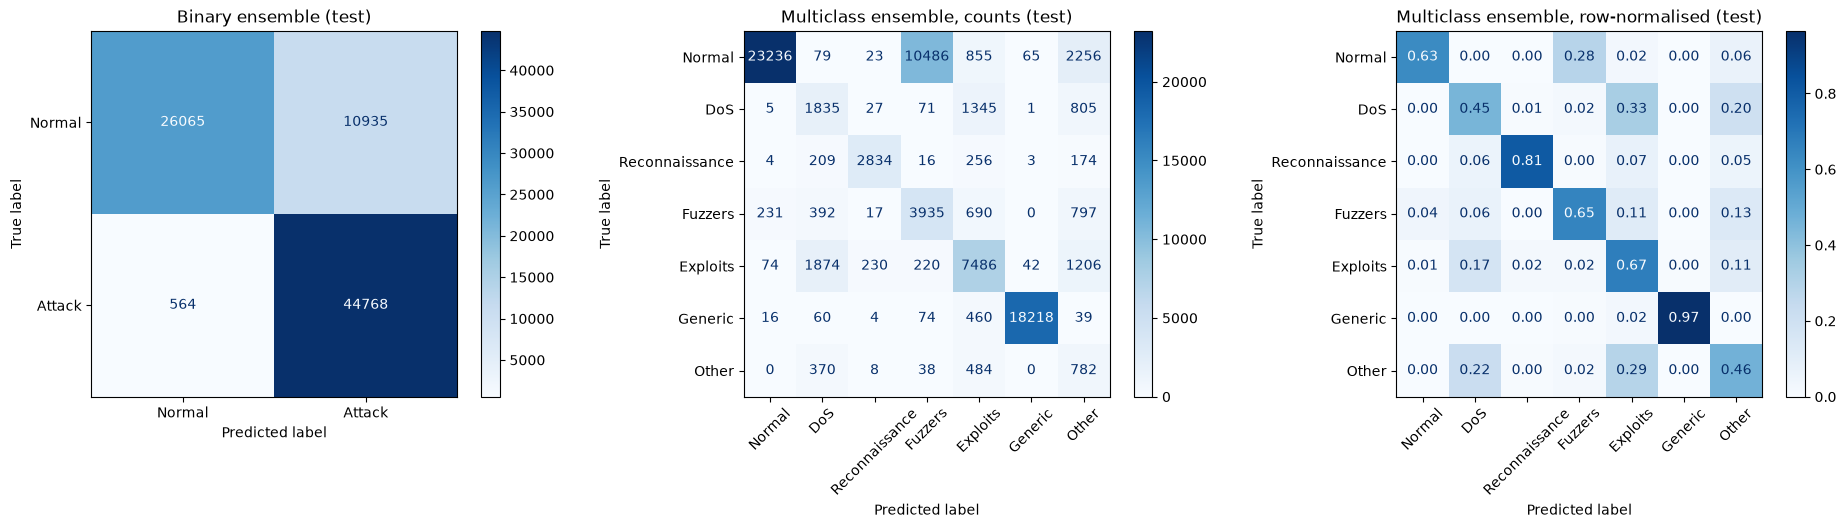

In [11]:
print(f"FINAL BINARY ensemble ({best_bin_method}), threshold {final_bin_thr:.3f}")
print(classification_report(yb_test, eb_pred, target_names=["Normal", "Attack"], digits=4))
print(f"FINAL MULTICLASS ensemble ({final_multi_method})")
print(classification_report(ym_test, final_multi_pred, labels=list(range(K)), target_names=class_names, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ConfusionMatrixDisplay.from_predictions(yb_test, eb_pred, display_labels=["Normal", "Attack"],
                                        cmap="Blues", ax=axes[0], values_format="d")
axes[0].set_title("Binary ensemble (test)")
ConfusionMatrixDisplay.from_predictions(ym_test, final_multi_pred, labels=list(range(K)), display_labels=class_names,
                                        cmap="Blues", ax=axes[1], values_format="d", xticks_rotation=45)
axes[1].set_title("Multiclass ensemble, counts (test)")
ConfusionMatrixDisplay.from_predictions(ym_test, final_multi_pred, labels=list(range(K)), display_labels=class_names,
                                        normalize="true", cmap="Blues", ax=axes[2], values_format=".2f", xticks_rotation=45)
axes[2].set_title("Multiclass ensemble, row-normalised (test)")
plt.tight_layout(); plt.show()

## 9. Decision layer

The ensemble produces an attack probability. The decision layer turns it into an action:

| Level | Rule |
|---|---|
| **High** | probability at or above the threshold that allows only `TARGET_FPR_HIGH` false alarms on validation |
| **Medium** | probability at or above the best-F1 threshold, but below High |
| **Unusual** | the ensemble says normal, but the **autoencoder** finds the flow unlike normal traffic (a possible unknown attack) |
| **Normal** | none of the above |

The attack family comes from the multiclass ensemble. DoS, Exploits and the rare attacks are reported as one family, because the models cannot reliably tell them apart without TTL features.

In [12]:
fpr_v, tpr_v, thr_v = roc_curve(yb_val, final_bin_v)
ok = np.flatnonzero(fpr_v <= TARGET_FPR_HIGH)
t_high = float(max(thr_v[ok[-1]], final_bin_thr)) if len(ok) else 1.0
t_med = float(final_bin_thr)
print(f"medium threshold (best F1): {t_med:.3f}    high threshold (FPR <= {TARGET_FPR_HIGH:.0%} on validation): {t_high:.3f}")

# optional: autoencoder as the 'unusual traffic' signal
ae_flag = np.zeros(len(X_test), dtype=bool)
ae_used = False
ae_file, ae_thr_file = Path(MODEL_DIR) / "autoencoder.keras", Path(MODEL_DIR) / "ae_threshold.json"
if ae_file.exists() and ae_thr_file.exists():
    import keras
    ae = keras.models.load_model(ae_file)
    ae_thr = json.loads(ae_thr_file.read_text())["threshold"]
    ae_score = np.mean((X_test - ae.predict(X_test, batch_size=4096, verbose=0)) ** 2, axis=1)
    ae_flag = ae_score >= ae_thr
    ae_used = True
print("autoencoder used for the 'unusual' level:", ae_used)

FAMILY = {"DoS": "DoS / Exploit-like", "Exploits": "DoS / Exploit-like", "Other": "DoS / Exploit-like",
          "Exploit-like": "DoS / Exploit-like", "Reconnaissance": "Reconnaissance / scanning",
          "Fuzzers": "Fuzzers", "Generic": "Generic (cipher) attack", "Normal": "Normal"}


def decide(p_attack, class_pred, unusual_flag):
    level = np.full(len(p_attack), "normal", dtype=object)
    level[unusual_flag] = "unusual"
    level[p_attack >= t_med] = "medium"
    level[p_attack >= t_high] = "high"
    family = np.array([FAMILY[class_names[c]] if lv in ("high", "medium") else "-" for c, lv in zip(class_pred, level)])
    return level, family


level, family = decide(final_bin_t, final_multi_pred, ae_flag)
names = np.array(class_names)[ym_test]
table = (pd.crosstab(pd.Series(names, name="true class"), pd.Series(level, name="level"), normalize="index") * 100)
table = table.reindex(index=class_names, columns=["high", "medium", "unusual", "normal"], fill_value=0).round(1)
table["detected (high+medium+unusual)"] = (100 - table["normal"]).round(1)
display(table)

normal_mask = yb_test == 0
print(f"normal flows raising a High alert:   {100 * np.mean(level[normal_mask] == 'high'):.2f}%")
print(f"normal flows raising any alert:      {100 * np.mean(level[normal_mask] != 'normal'):.2f}%")
high = level == "high"
print(f"precision of High alerts:            {100 * np.mean(yb_test[high] == 1):.2f}%   ({high.sum():,} High alerts)")

medium threshold (best F1): 0.316    high threshold (FPR <= 1% on validation): 0.768
autoencoder used for the 'unusual' level: True


level,high,medium,unusual,normal,detected (high+medium+unusual)
true class,,,,,
Normal,7.1,22.4,5.2,65.3,34.7
DoS,98.3,1.7,0.0,0.0,100.0
Reconnaissance,98.7,1.3,0.0,0.0,100.0
Fuzzers,47.6,44.2,0.8,7.4,92.6
Exploits,96.9,2.7,0.0,0.4,99.6
Generic,99.8,0.2,0.0,0.0,100.0
Other,95.1,4.2,0.1,0.7,99.3


normal flows raising a High alert:   7.13%
normal flows raising any alert:      34.72%
precision of High alerts:            94.03%   (44,209 High alerts)


## 10. Save everything the live detector needs

`ensemble_config.json` holds the member lists, weights, thresholds, class scales and family map. The stackers are saved as joblib files. `final_results_test.csv` holds the test table for your report.

In [13]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)
joblib.dump(stack_bin, mdir / "ensemble_stack_binary.joblib")
joblib.dump(stack_multi, mdir / "ensemble_stack_multiclass.joblib")

config = {
    "members_binary": members_bin, "members_multiclass": members_multi,
    "binary_method": best_bin_method, "binary_weights": dict(zip(members_bin, map(float, w_bin))),
    "multiclass_method": final_multi_method, "multiclass_weights": dict(zip(members_multi, map(float, w_multi))),
    "class_scale": dict(zip(class_names, map(float, class_scale))),
    "threshold_medium": t_med, "threshold_high": t_high, "target_fpr_high": TARGET_FPR_HIGH,
    "autoencoder_used": ae_used, "family_map": FAMILY, "class_names": class_names,
    "individual_binary_thresholds": {t: float(bin_thr[t]) for t in members_bin},
}
(mdir / "ensemble_config.json").write_text(json.dumps(config, indent=2))

binary_all.to_csv(mdir / "final_results_test_binary.csv", index=False)
multiclass_all.to_csv(mdir / "final_results_test_multiclass.csv", index=False)
print("saved ensemble_config.json, the stacking models and the final result tables to", mdir)

saved ensemble_config.json, the stacking models and the final result tables to models


## 11. Using it later (live pipeline)

The live detector scores each flow with the member models, combines them with the saved method, and applies `decide()`. The next step is wiring that into `live_detector.py`, plus a per-source rule: several alerts from one source IP within a short window become one "possible scan or flood from IP X" alert.